# Welcome to my NFL Stats Predictor


In [71]:
# Loading All Packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All packages loaded successfully.")

All packages loaded successfully.


In [72]:
# Loading my Play By Play Data
df_2023 = pd.read_csv('./data/play_by_play_2023.csv')
df_2024 = pd.read_csv('./data/play_by_play_2024.csv')
df_2025 = pd.read_csv('./data/play_by_play_2025.csv')

df_combined = pd.concat([df_2023, df_2024, df_2025], ignore_index=True)

print("Combined data shape:", df_combined.shape)
print("Seasons in combined data:", df_combined['season'].unique())

# First Look at Combined Data
print("\nFirst 5 Rows of Combined Data: ")
print(df_combined.head())

print("\nData Shape (Rows, Columns): ")
print(df_combined.shape)

print("\nData Columns: ")
print(df_combined.columns.tolist())

C:\Users\user1\AppData\Local\Temp\ipykernel_16352\1094582618.py:2: DtypeWarning: Columns (45,179,180,182,183,189,190,197,198,203,204,205,206,218,219,220,222,224,226,253,254,255,260,262,263,283,284,332) have mixed types. Specify dtype option on import or set low_memory=False.
  df_2023 = pd.read_csv('./data/play_by_play_2023.csv')
C:\Users\user1\AppData\Local\Temp\ipykernel_16352\1094582618.py:3: DtypeWarning: Columns (179,180,182,183,189,190,197,198,203,204,205,206,213,214,218,219,220,222,224,226,233,234,235,236,237,238,248,249,253,254,255,260,262,263,283,284) have mixed types. Specify dtype option on import or set low_memory=False.
  df_2024 = pd.read_csv('./data/play_by_play_2024.csv')
C:\Users\user1\AppData\Local\Temp\ipykernel_16352\1094582618.py:4: DtypeWarning: Columns (179,180,182,183,203,204,205,206,218,219,220,222,224,226,233,234,235,236,237,238,253,254,255,260,262,263,283,284,332) have mixed types. Specify dtype option on import or set low_memory=False.
  df_2025 = pd.read_cs

Combined data shape: (129579, 372)
Seasons in combined data: [2023 2024 2025]

First 5 Rows of Combined Data: 
   play_id          game_id  old_game_id home_team away_team season_type  \
0        1  2023_01_ARI_WAS   2023091007       WAS       ARI         REG   
1       39  2023_01_ARI_WAS   2023091007       WAS       ARI         REG   
2       55  2023_01_ARI_WAS   2023091007       WAS       ARI         REG   
3       77  2023_01_ARI_WAS   2023091007       WAS       ARI         REG   
4      102  2023_01_ARI_WAS   2023091007       WAS       ARI         REG   

   week posteam posteam_type defteam  ... out_of_bounds  home_opening_kickoff  \
0     1     NaN          NaN     NaN  ...             0                     1   
1     1     WAS         home     ARI  ...             0                     1   
2     1     WAS         home     ARI  ...             0                     1   
3     1     WAS         home     ARI  ...             0                     1   
4     1     WAS         hom

Explore Features
- What Correlates with Touchdowns?
- Use Yards and Previous Season Performance to Predict Touchdowns?

In [73]:
# Use Basic Quarterback Stats

qb_feats = ['season', 'passer_id', 'passer', 'pass', 
            'complete_pass', 'interception', 
            'sack', 'yards_gained', 'touchdown']

# Group By Features to Analyze Quarterback Performance
groupby_feats = ['season', 'passer_id', 'passer']

# Making a DataFrame with Quarterback Stats
qb_df = (df_combined.loc[:, qb_feats].groupby(groupby_feats, as_index=False).sum())

print("\nQuarterback Season Totals Created: ")
print(f"New Shape: {qb_df.shape}")
print("\nSamples of Quarterback Seasons: ")
print(qb_df.sample(10))




Quarterback Season Totals Created: 
New Shape: (314, 9)

Samples of Quarterback Seasons: 
     season   passer_id        passer  pass  complete_pass  interception  \
51     2023  00-0034771     M.Rudolph   128           77.0           1.0   
28     2023  00-0033009        T.Boyd     1            0.0           1.0   
313    2025  00-0040743      T.Shough   145           81.0           3.0   
129    2024  00-0029692       B.Anger     2            1.0           0.0   
82     2023  00-0036626       D.Brown     1            1.0           0.0   
139    2024  00-0032065      B.Pinion     1            0.0           0.0   
119    2023  00-0039164  A.Richardson   107           50.0           1.0   
12     2023  00-0029692       B.Anger     1            0.0           0.0   
8      2023  00-0028872      J.Hekker     1            1.0           0.0   
24     2023  00-0032268     M.Mariota    28           15.0           1.0   

     sack  yards_gained  touchdown  
51    7.0         919.0        5.0 

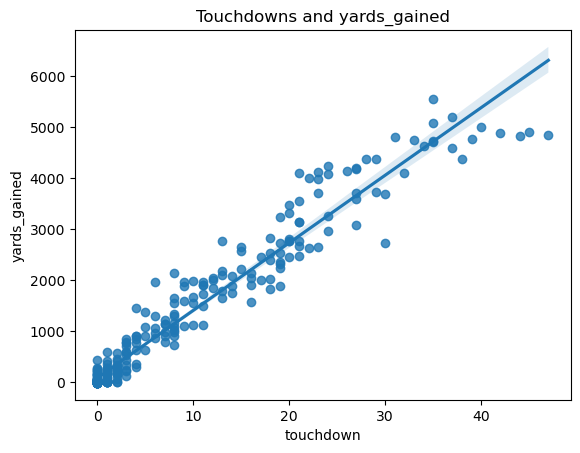

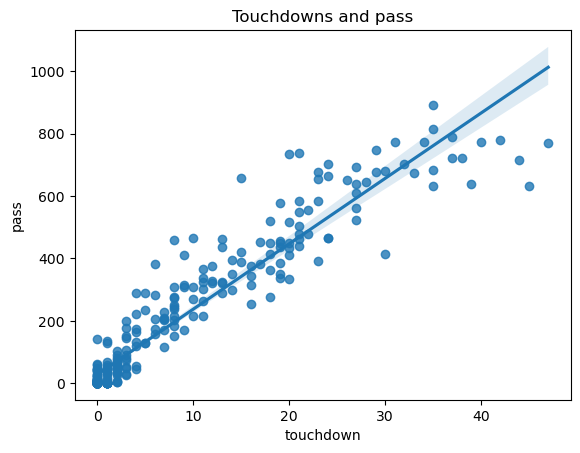

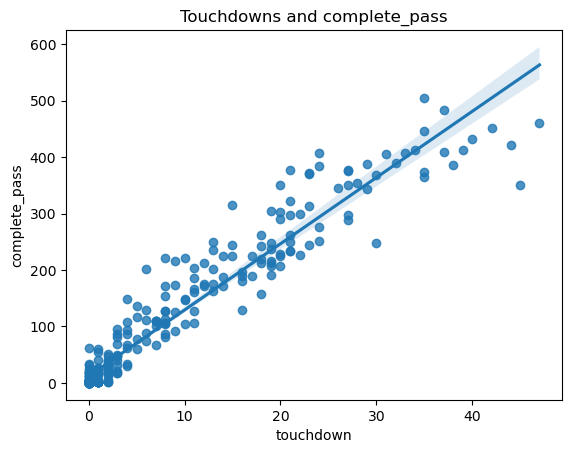

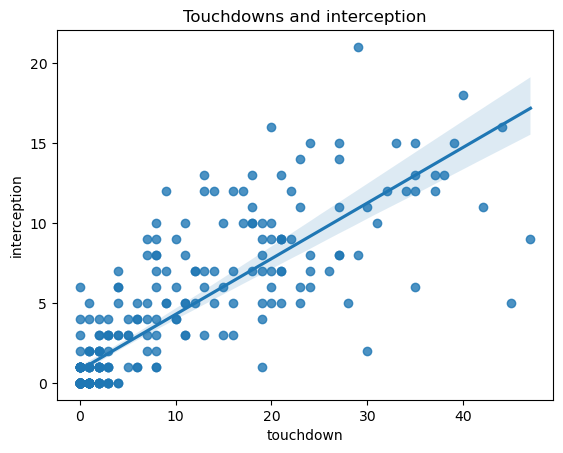

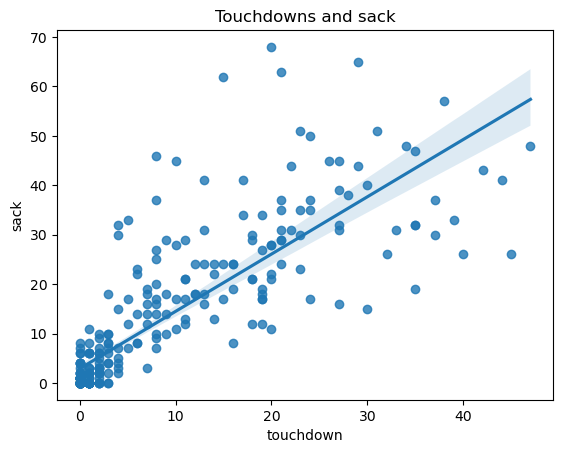

In [74]:
# What Correlates with Touchdowns?

for y in ['yards_gained', 'pass', 'complete_pass', 'interception', 'sack']:
    sns.regplot(data=qb_df, x='touchdown', y=y,)
    plt.title(f"Touchdowns and {y}")
    plt.show()

In [92]:
# Apparently knowing yards gained, 
# completed passes, attempted passes, 
# interceptions, and sacks all correlate with
# touchdowns. Let's see if this is the case for
# _next season_ touchdowns 

# Making a Copy of the QB DataFrame
_df = qb_df.copy()

# Add 1 to Prev Season (so 2024 becomes "predicted 2025")
_df['season'] = _df['season'].add(1)

# Merge to create next-season prediction dataset
new_qb_df = qb_df.merge(_df, 
                       on=['season', 'passer_id', 'passer'], 
                       suffixes=('', '_prev'), 
                       how='left')

print("New dataset shape:", new_qb_df.shape)
print("\nSample of next-season prediction data:")
new_qb_df.sample(10)

New dataset shape: (314, 15)

Sample of next-season prediction data:


,season,passer_id,passer,pass,complete_pass,interception,sack,yards_gained,touchdown,pass_prev,complete_pass_prev,interception_prev,sack_prev,yards_gained_prev,touchdown_prev
64,2023,00-0035289,G.Minshew II,579,305.0,9.0,34.0,3235.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN
255,2025,00-0034348,C.Sutton,1,0.0,0.0,1.0,-5.0,0.0,2.0,2.0,0.0,0.0,30.0,1.0
71,2023,00-0035993,T.Huntley,48,21.0,0.0,4.0,216.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN
242,2025,00-0031503,J.Winston,75,37.0,2.0,3.0,567.0,2.0,345.0,181.0,12.0,24.0,2045.0,16.0
175,2024,00-0035228,K.Murray,653,372.0,11.0,30.0,3988.0,23.0,322.0,176.0,5.0,18.0,1843.0,12.0
194,2024,00-0036945,J.Fields,214,106.0,1.0,16.0,1095.0,8.0,478.0,227.0,9.0,44.0,2637.0,22.0
0,2023,00-0023459,A.Rodgers,3,0.0,0.0,1.0,-10.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
118,2023,00-0039163,C.Stroud,645,354.0,5.0,38.0,4383.0,28.0,NaN,NaN,NaN,NaN,NaN,NaN
136,2024,00-0031503,J.Winston,345,181.0,12.0,24.0,2045.0,16.0,52.0,25.0,3.0,2.0,251.0,2.0
279,2025,00-0036898,D.Mills,173,88.0,1.0,8.0,867.0,6.0,41.0,20.0,0.0,2.0,203.0,0.0


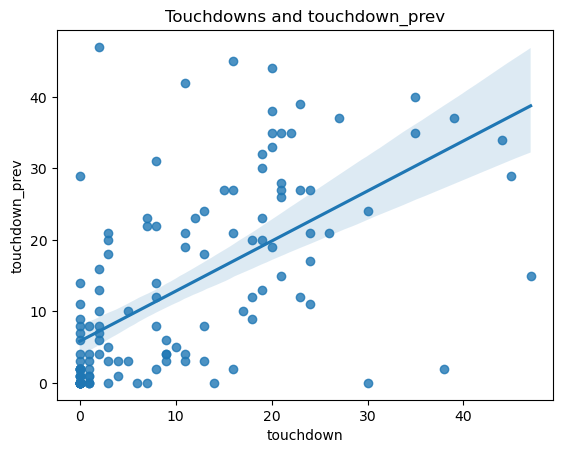

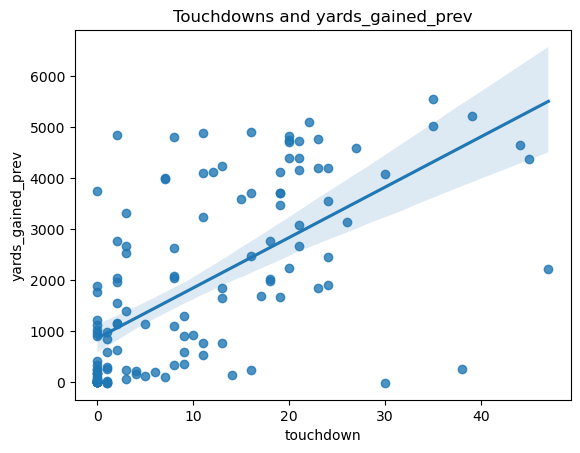

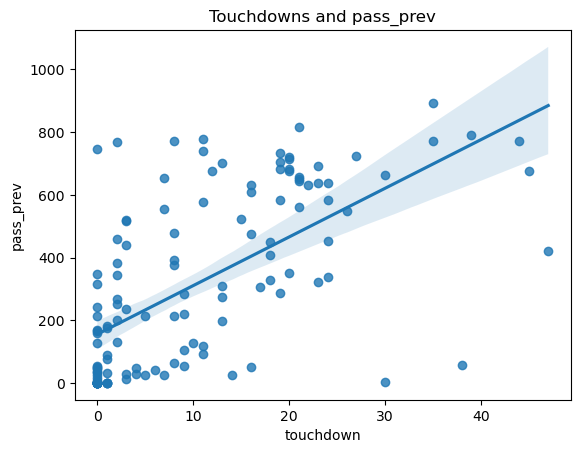

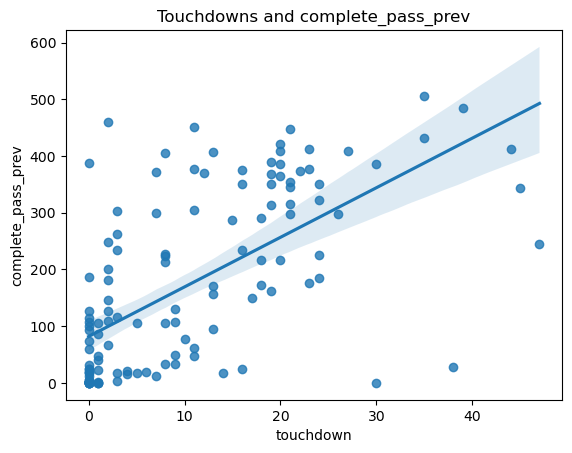

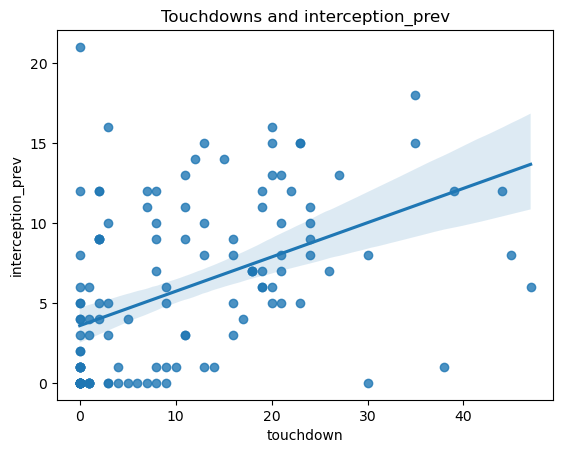

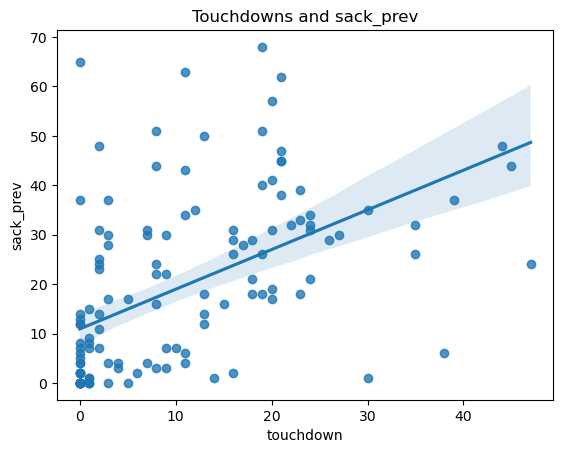

In [76]:
# Seeing What Correlates with Next Season Touchdowns

for y in ['touchdown_prev', 'yards_gained_prev', 
          'pass_prev', 'complete_pass_prev', 
          'interception_prev', 'sack_prev']:
    sns.regplot(data=new_qb_df, x='touchdown', y=y,)
    plt.title(f"Touchdowns and {y}")
    plt.show()

In [77]:
# Using previous season information, we can see 
# there are year-to-year correlations with
# touchdowns. Let's use previous season performance
# to estimate touchdowns thrown for the next season

Machine Learning 
- Simple Linear Model
- Trains with Previous Years Stats, Tests on Next Year
- Save out of Sample Test Results
- Visualize and Run Basic Stats




In [78]:
# Loading ML and Stats Packages
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

new_qb_df.sample(10)

,season,passer_id,passer,pass,complete_pass,interception,sack,yards_gained,touchdown,pass_prev,complete_pass_prev,interception_prev,sack_prev,yards_gained_prev,touchdown_prev
211,2024,00-0038476,T.DeVito,61,31.0,0.0,6.0,257.0,0.0,243.0,114.0,3.0,37.0,1028.0,8.0
43,2023,00-0033949,J.Dobbs,519,262.0,10.0,30.0,2530.0,18.0,NaN,NaN,NaN,NaN,NaN,NaN
96,2023,00-0037304,Co.Heyward,1,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
86,2023,00-0036913,K.Toney,1,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
197,2024,00-0036972,M.Jones,309,171.0,8.0,14.0,1657.0,8.0,394.0,224.0,12.0,22.0,2078.0,14.0
196,2024,00-0036971,T.Lawrence,329,172.0,7.0,18.0,2016.0,12.0,677.0,370.0,14.0,35.0,4122.0,23.0
261,2025,00-0034857,J.Allen,412,228.0,9.0,28.0,2813.0,20.0,684.0,365.0,6.0,19.0,4714.0,35.0
59,2023,00-0035100,J.Browning,298,171.0,7.0,24.0,1892.0,14.0,NaN,NaN,NaN,NaN,NaN,NaN
158,2024,00-0034162,J.Scott,1,1.0,0.0,0.0,3.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
140,2024,00-0032268,M.Mariota,56,34.0,0.0,3.0,360.0,4.0,28.0,15.0,1.0,3.0,170.0,1.0


In [ ]:
# Training our Data on One Season, Testing on the Next using Train Test Splitting.


# Previous Season Performance as Our Features For Our Model
features = ['pass_prev', 
            'yards_gained_prev', 'touchdown_prev']

# We are Predicting "Current" Season Touchdowns
target = 'touchdown'

# Subset of Data with No Null Values
model_data = (new_qb_df.dropna(subset=features + [target]))

# Train on 2024 Data 
train_data = (model_data.loc[model_data['season'] == 2024])

# Test on 2025 Data
test_data = (model_data.loc[model_data['season'] == 2025])

print(f"Training Data: {len(train_data)} quarterback seasons")
print(f"Testing Data: {len(test_data)} quarterback seasons")

# Initialize Linear Regression Model
lr_model = LinearRegression()

# Fit / "Train" Model on Training Data
lr_model.fit(train_data.loc[:, features], train_data[target])

# Predict on Test Data
preds = lr_model.predict(test_data.loc[:, features])
preds = pd.Series(preds, index=test_data.index)

# Join Predictions to Test DataFrame
test_data['preds'] = preds

Training Data: 72 quarterback seasons
Testing Data: 57 quarterback seasons


C:\Users\user1\AppData\Local\Temp\ipykernel_16352\906816956.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_data['completion_pct_prev'] = model_data['complete_pass_prev'] / model_data['pass_prev']
C:\Users\user1\AppData\Local\Temp\ipykernel_16352\906816956.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_data['yards_per_attempt_prev'] = model_data['yards_gained_prev'] / model_data['pass_prev']
C:\Users\user1\AppData\Local\Temp\ipykernel_16352\906816956.py:13: SettingWithCopyWarning: 
A 

In [126]:
# Statistics on Quality of Predictions
rmse = mean_squared_error(test_data['touchdown'], test_data['preds']) ** 0.5
r2 = pearsonr(test_data['touchdown'], test_data['preds'])[0] ** 2
print(f"RMSE: {rmse:.2f}")
print(f"R^2: {r2:.2f}")

RMSE: 9.53
R^2: 0.00


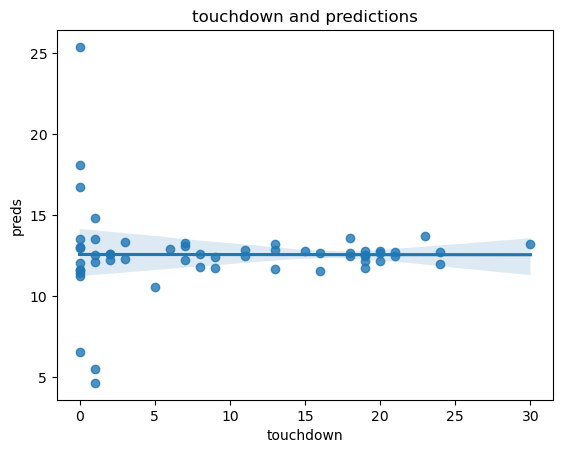

In [127]:
# Visualizing Predictions
sns.regplot(data=test_data, x='touchdown', y='preds')
plt.title('touchdown and predictions')
plt.show()

In [128]:
test_data.loc[:, ['season', 'passer_id', 'passer', 'touchdown', 'preds']].sort_values('touchdown', ascending=False).head(25)

,season,passer_id,passer,touchdown,preds
235,2025,00-0026498,M.Stafford,30.0,13.200445
246,2025,00-0033077,D.Prescott,24.0,12.751638
299,2025,00-0039851,D.Maye,24.0,11.975637
247,2025,00-0033106,J.Goff,23.0,13.740256
252,2025,00-0033873,P.Mahomes,21.0,12.499378
274,2025,00-0036355,J.Herbert,21.0,12.732572
262,2025,00-0034869,S.Darnold,20.0,12.185580
260,2025,00-0034855,B.Mayfield,20.0,12.796248
261,2025,00-0034857,J.Allen,20.0,12.664256
302,2025,00-0039918,C.Williams,19.0,11.758014


In [129]:
# Check what's driving these extreme predictions
print("=== PREDICTION ANALYSIS ===")

# Look at the feature values for the most extreme predictions
extreme_cases = test_data.nlargest(5, 'preds')[['passer', 'touchdown', 'preds'] + features]
print("Highest predictions:")
print(extreme_cases)

# Check the model coefficients to see what it's learning
print("\nModel coefficients:")
for feature, coef in zip(features, lr_model.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {lr_model.intercept_:.4f}")

# Check for data issues
print(f"\nTraining data size: {len(train_data)}")
print(f"Max touchdowns in training: {train_data['touchdown'].max()}")

=== PREDICTION ANALYSIS ===
Highest predictions:
            passer  touchdown      preds  yards_per_attempt_prev  \
256        K.Allen        0.0  25.371226               19.000000   
290       T.Bagent        0.0  18.108903                5.500000   
241  T.Bridgewater        0.0  16.764029                3.000000   
295       J.Milton        1.0  14.792694                7.470588   
247         J.Goff       23.0  13.740256                7.476489   

     td_per_attempt_prev  completion_pct_prev  
256             0.000000             1.000000  
290             0.000000             1.000000  
241             0.000000             1.000000  
295             0.029412             0.647059  
247             0.061129             0.647335  

Model coefficients:
yards_per_attempt_prev: 0.5379
td_per_attempt_prev: -33.3664
completion_pct_prev: 9.6189
Intercept: 5.5312

Training data size: 72
Max touchdowns in training: 47.0
